# 💰 Kişisel Finans ve Harcama Takip Sistemi

**Öğrenci Adı Soyadı:** Semih Berke Kolatan  
**Öğrenci Numarası:** 24097002  
**Bölüm:** Bilişim Sistemleri Ve Teknolojileri  
**Ders:** BGY210 – Python Programlama II  
**Dönem:** 2025–2026 Bahar  
**GitHub Repo:** https://github.com/KULLANICI_ADI/24097002-SemihBerkeKolatan-PythonProje

---

## Proje Açıklaması

Bu proje, kullanıcıların **gelir ve giderlerini** kayıt altına almasını,
listeleme yapmasını, finansal analiz gerçekleştirmesini ve sonuçları
grafiklerle görselleştirmesini sağlayan konsol tabanlı bir Python uygulamasıdır.

## Modüller

| Dosya | Açıklama |
|---|---|
| `finans_modeli.py` | `Islem` sınıfı (OOP) |
| `utils.py` | Yardımcı fonksiyonlar (ID, tarih, sayı kontrolü, menü) |
| `islem_yonetimi.py` | Gelir/gider ekleme, listeleme, silme |
| `dosya_islemleri.py` | CSV okuma/yazma |
| `analiz.py` | Pandas & NumPy analizleri |
| `gorsellestirme.py` | Matplotlib & Seaborn grafikleri |
| `main.py` | Ana konsol uygulaması |

## Kullanılan Veri Yapıları

- `gelirler = []` → `Islem` nesnelerinden oluşan liste
- `giderler = []` → `Islem` nesnelerinden oluşan liste
- `pandas.DataFrame` → Analiz ve görselleştirme için
- `numpy.ndarray` → İstatistiksel hesaplamalar için

---
## 1. Kütüphane ve Modül İmportları

In [1]:
# Standart kütüphaneler
import csv
from datetime import datetime

# Veri analizi kütüphaneleri
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Proje modülleri
from finans_modeli   import Islem
from utils           import yeni_id_olustur, tarih_kontrol, sayi_kontrol, menu_goster
from islem_yonetimi  import gelir_ekle, gider_ekle, islemleri_listele, islem_sil
from dosya_islemleri import csv_kaydet, csv_oku
from analiz          import verileri_dataframe_yap, toplam_gelir_gider, aylik_analiz, numpy_istatistik
from gorsellestirme  import aylik_grafik, gelir_gider_bar, pasta_grafik

print('✅ Tüm modüller başarıyla yüklendi.')

✅ Tüm modüller başarıyla yüklendi.


---
## 2. OOP – Islem Sınıfı Testi

In [2]:
# Islem nesnesi oluşturma ve str gösterimi
ornek = Islem(id=1, tutar=5000.0, tarih='2026-06-01', aciklama='Maaş', tip='gelir')
print(ornek)
print('Sözlük formu:', ornek.to_dict())

[1] GELIR  | 2026-06-01 |    5000.00 TL | Maaş
Sözlük formu: {'id': 1, 'tutar': 5000.0, 'tarih': '2026-06-01', 'aciklama': 'Maaş', 'tip': 'gelir'}


---
## 3. Örnek Verilerle Listeleri Doldurma

In [3]:
# Başlangıç listeleri
gelirler = []
giderler = []

# Örnek veriler – gerçek kullanımda kullanıcı konsoldan girer
ornek_gelirler = [
    Islem(1, 15000, '2026-04-01', 'Maaş',        'gelir'),
    Islem(2,  2000, '2026-04-15', 'Freelance',    'gelir'),
    Islem(3, 15000, '2026-05-01', 'Maaş',        'gelir'),
    Islem(4,  1500, '2026-05-20', 'Kira Geliri', 'gelir'),
]

ornek_giderler = [
    Islem(1,  4500, '2026-04-05', 'Kira',           'gider'),
    Islem(2,  1200, '2026-04-10', 'Market',         'gider'),
    Islem(3,   350, '2026-04-18', 'Fatura',         'gider'),
    Islem(4,  4500, '2026-05-05', 'Kira',           'gider'),
    Islem(5,   900, '2026-05-12', 'Market',         'gider'),
    Islem(6,   600, '2026-05-25', 'Ulaşım',        'gider'),
]

gelirler.extend(ornek_gelirler)
giderler.extend(ornek_giderler)

print(f'Yüklendi: {len(gelirler)} gelir, {len(giderler)} gider')

Yüklendi: 4 gelir, 6 gider


---
## 4. İşlemleri Listeleme

In [4]:
islemleri_listele(gelirler, giderler)


 📋 TÜM İŞLEMLER

💚 GELİRLER:
-------------------------------------------------------
  [1] GELIR  | 2026-04-01 |   15000.00 TL | Maaş
  [2] GELIR  | 2026-04-15 |    2000.00 TL | Freelance
  [3] GELIR  | 2026-05-01 |   15000.00 TL | Maaş
  [4] GELIR  | 2026-05-20 |    1500.00 TL | Kira Geliri

🔴 GİDERLER:
-------------------------------------------------------
  [1] GIDER  | 2026-04-05 |    4500.00 TL | Kira
  [2] GIDER  | 2026-04-10 |    1200.00 TL | Market
  [3] GIDER  | 2026-04-18 |     350.00 TL | Fatura
  [4] GIDER  | 2026-05-05 |    4500.00 TL | Kira
  [5] GIDER  | 2026-05-12 |     900.00 TL | Market
  [6] GIDER  | 2026-05-25 |     600.00 TL | Ulaşım

  Toplam Gelir :   33500.00 TL
  Toplam Gider :   12050.00 TL
  Net Bakiye   :   21450.00 TL  ✅


---
## 5. Dosya İşlemleri – CSV Kaydet & Oku

In [5]:
# CSV'ye kaydet
csv_kaydet('finans_verileri.csv', gelirler, giderler)

# CSV'den geri oku
g2, gid2 = csv_oku('finans_verileri.csv')
print(f'Geri yüklenen: {len(g2)} gelir, {len(gid2)} gider')

✅ 10 işlem 'finans_verileri.csv' dosyasına kaydedildi.
✅ 'finans_verileri.csv' dosyasından 4 gelir, 6 gider yüklendi.
Geri yüklenen: 4 gelir, 6 gider


---
## 6. Veri Analizi (Pandas & NumPy)

In [6]:
df = verileri_dataframe_yap(gelirler, giderler)
print('DataFrame ilk 5 satır:')
df.head()

DataFrame ilk 5 satır:


,id,tutar,tarih,aciklama,tip,ay
0,1,15000.0,2026-04-01,Maaş,gelir,2026-04
1,2,2000.0,2026-04-15,Freelance,gelir,2026-04
2,3,15000.0,2026-05-01,Maaş,gelir,2026-05
3,4,1500.0,2026-05-20,Kira Geliri,gelir,2026-05
4,1,4500.0,2026-04-05,Kira,gider,2026-04


In [7]:
# Toplam gelir / gider / bakiye
ozet = toplam_gelir_gider(df)


📊 FİNANSAL ÖZET
-----------------------------------
  Toplam Gelir  :   33500.00 TL
  Toplam Gider  :   12050.00 TL
  Net Bakiye    :   21450.00 TL  ✅


In [8]:
# Aylık analiz
aylik_df = aylik_analiz(df)


📅 AYLIK ANALİZ
-------------------------------------------------------
tip      Gelir (TL)  Gider (TL)  Net Bakiye (TL)
ay                                              
2026-04     17000.0      6050.0          10950.0
2026-05     16500.0      6000.0          10500.0


In [9]:
# NumPy istatistikleri
istatistik = numpy_istatistik(df)


📈 NUMPY İSTATİSTİKLERİ (Tüm İşlemler)
----------------------------------------
  Ortalama Tutar   :    4555.00 TL
  Minimum Tutar    :     350.00 TL
  Maksimum Tutar   :   15000.00 TL
  Standart Sapma   :    5403.72 TL


---
## 7. Görselleştirme

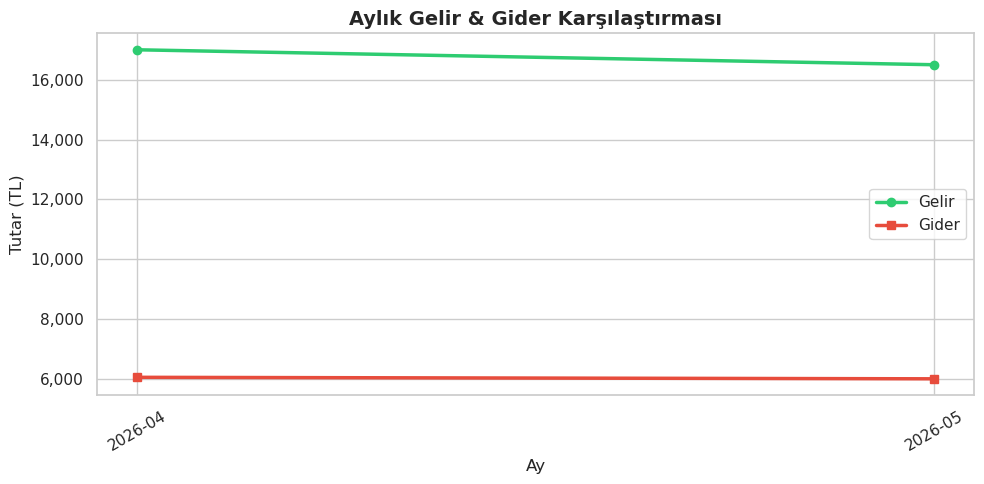

💾 Grafik 'aylik_grafik.png' olarak kaydedildi.


In [10]:
# Aylık çizgi grafik
aylik_grafik(df)

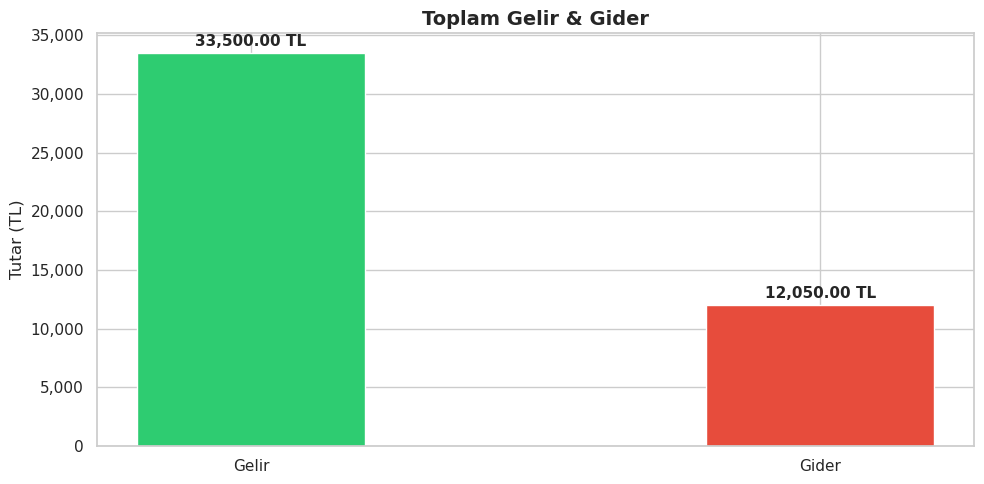

💾 Grafik 'gelir_gider_bar.png' olarak kaydedildi.


In [11]:
# Sütun grafik
gelir_gider_bar(df)

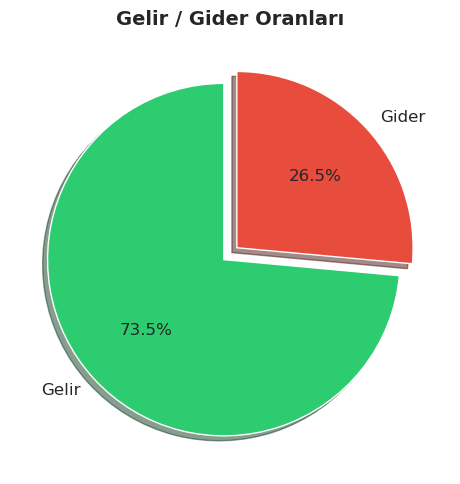

💾 Grafik 'pasta_grafik.png' olarak kaydedildi.


In [12]:
# Pasta grafik
pasta_grafik(df)

---
## 8. Konsol Uygulamasını Çalıştırma

Aşağıdaki hücreyi çalıştırarak **tam konsol menüsünü** başlatabilirsiniz.  
Alternatif olarak terminalde `python main.py` komutunu kullanabilirsiniz.

In [13]:
# Tam konsol uygulaması – interaktif giriş gerektirir
# Notebook ortamında test etmek için main.py'yi terminalde çalıştırın:
#   python main.py

# Menü önizlemesi:
menu_goster()


   💰  KİŞİSEL FİNANS TAKİP SİSTEMİ  💰
  1. Gelir Ekle
  2. Gider Ekle
  3. İşlemleri Listele
  4. Analiz Yap
  5. Grafik Göster
  6. CSV Kaydet / Yükle
  7. Çıkış
